# 12-3 AWS Backup 실습 결과 퀴즈
[가이드북](https://bsmkorea1216sj.github.io/cloud_architecture/week/12/session/3)의 콘솔 실습을 마치고 참여하세요. 정리 전에 원본·복원 인스턴스 ID의 끝 4자리, 웹 페이지에서 비교한 문구, 백업·복원 작업 상태를 기록해 두면 AWS 자원을 정리한 뒤에도 풀 수 있습니다. AWS 키 입력이나 새 스택 생성은 필요 없습니다.

자신의 Drive에 사본을 저장한 뒤 위에서 아래로 실행하세요. 자동 채점 4점과 서술형 1문항입니다.

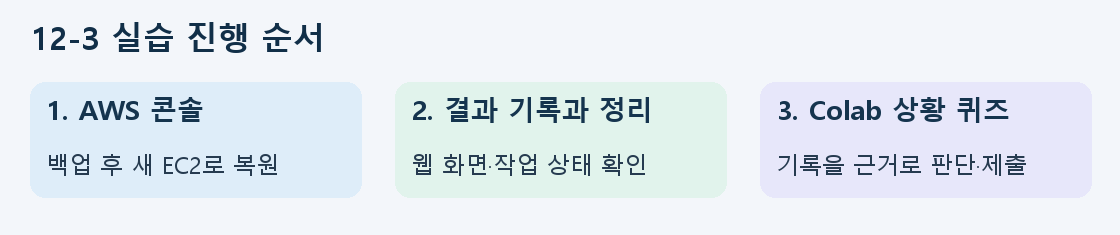

In [ ]:
scores = {}
def choice(number, prompt, options, correct, why):
    print(prompt)
    for i, option in enumerate(options, 1):
        print(f"{i}. {option}")
    while True:
        answer = input("번호 입력: ").strip()
        if answer in [str(i) for i in range(1, len(options)+1)]: break
        print("보기 중 번호를 선택하세요.")
    scores[number] = int(answer == str(correct))
    print(("정답. " if scores[number] else "다시 생각해 보세요. ") + why)

In [ ]:
choice(1, "두 EC2에 Project=CloudArchitect가 있습니다. A만 Week=Week12-3이고 B는 Week=Week11-3입니다. 가이드의 예약 백업 대상은?", ["A만", "B만", "둘 다"], 1, "Project와 Week 조건을 동시에 만족하는 A만 포함됩니다.")

In [ ]:
choice(2, "일일 백업을 7일간 보존합니다. 어제 14:17 상태로 복원하려면 무엇을 확인할까요?", ["7일 이내면 모든 분을 선택할 수 있다", "그 시각에 해당하는 복구 시점이 있는지 본다", "원본 인스턴스의 현재 IP를 본다"], 2, "일일은 빈도, 7일은 보존 기간입니다. 이 실습에서는 생성되어 남아 있는 복구 시점을 선택합니다.")

In [ ]:
choice(3, "오늘의 온디맨드 백업이 Completed입니다. 내일 예약 백업 성공 여부를 어떻게 판정할까요?", ["오늘 수동 백업이 성공했으므로 성공이다", "볼트 이름이 있으면 성공이다", "예약 시각 이후 해당 계획의 대상과 작업 상태를 확인한다"], 3, "수동 작업과 예약 작업은 별개입니다. 계획·대상·작업 결과를 함께 확인합니다.")

## 상황 4 · 내 복원 결과 판독 (서술형)
두 인스턴스의 끝 4자리만 기록하세요. 서로 다른 인스턴스인지 전체 ID로 직접 대조하고, 실제 브라우저에서 열린 문구 한 가지를 근거로 적습니다. 일치 여부는 본인 화면을 기준으로 작성합니다.

In [ ]:
import re
def suffix(label):
    while True:
        value = input(label + " ID 끝 4자리: ").strip().lower()
        if re.fullmatch("[0-9a-f]{4}", value): return value
        print("16진수 네 글자를 입력하세요.")
source_id = suffix("원본")
restored_id = suffix("복원")
evidence = input("두 웹 화면에서 확인한 문구와 일치 여부(실패 시 관찰한 현상): ").strip()
if not evidence: raise ValueError("웹 화면에서 관찰한 결과를 입력하세요.")
print("제출 기록:",source_id,restored_id,evidence)
print("자가 점검: 서로 다른 전체 ID인지, 복원 서버 주소에서 기대한 콘텐츠가 실제로 보였는지 확인하세요.")

In [ ]:
print("14:00 주문 중단 / 13:50 데이터로 복원 / 14:20 복원 작업 완료 / 14:35 첫 주문 성공")
print("목표는 RPO 15분, RTO 30분입니다.")
gap = input("데이터 공백은 몇 분? ").strip()
down = input("고객의 서비스 중단은 몇 분? ").strip()
judgment = input("충족한 목표는? RPO / RTO / 둘 다 / 없음: ").strip().upper()
scores[5] = int(gap == "10" and down == "35" and judgment == "RPO")
print("정답." if scores[5] else "계산을 다시 확인하세요.")
print("14:00−13:50 = 10분으로 RPO 충족. 14:35−14:00 = 35분으로 RTO 초과. 복원 작업 완료 시각과 주문 재개 시각을 구분합니다.")

In [ ]:
if set(scores) != {1,2,3,5} or not globals().get("evidence"):
    print("앞의 상황 1~5를 모두 실행한 뒤 다시 확인하세요.")
else:
    print(f"자동 채점 {sum(scores.values())}/4점")
    print("서술형(강사 확인):",source_id,restored_id,evidence)
    print("이 셀의 출력과 콘솔에서 기록한 백업·복원 작업 상태를 제출하세요.")